In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Marketing Funnel Analysis Project Started!")

Marketing Funnel Analysis Project Started!


In [2]:
# Load Marketing Funnel Datasets

data_folder = "../data"

leads = pd.read_csv(
    os.path.join(data_folder, "olist_marketing_qualified_leads_dataset.csv")
)

deals = pd.read_csv(
    os.path.join(data_folder, "olist_closed_deals_dataset.csv")
)

print("LEADS DATASET")
print(leads.shape)
display(leads.head())

print("\nCLOSED DEALS DATASET")
print(deals.shape)
display(deals.head())

LEADS DATASET
(8000, 4)


,mql_id,first_contact_date,landing_page_id,origin
0,dac32acd4db4c29c230538b72f8dd87d,2018-02-01,88740e65d5d6b056e0cda098e1ea6313,social
1,8c18d1de7f67e60dbd64e3c07d7e9d5d,2017-10-20,007f9098284a86ee80ddeb25d53e0af8,paid_search
2,b4bc852d233dfefc5131f593b538befa,2018-03-22,a7982125ff7aa3b2054c6e44f9d28522,organic_search
3,6be030b81c75970747525b843c1ef4f8,2018-01-22,d45d558f0daeecf3cccdffe3c59684aa,email
4,5420aad7fec3549a85876ba1c529bd84,2018-02-21,b48ec5f3b04e9068441002a19df93c6c,organic_search



CLOSED DEALS DATASET
(842, 14)


,mql_id,seller_id,sdr_id,sr_id,won_date,business_segment,lead_type,lead_behaviour_profile,has_company,has_gtin,average_stock,business_type,declared_product_catalog_size,declared_monthly_revenue
0,5420aad7fec3549a85876ba1c529bd84,2c43fb513632d29b3b58df74816f1b06,a8387c01a09e99ce014107505b92388c,4ef15afb4b2723d8f3d81e51ec7afefe,2018-02-26 19:58:54,pet,online_medium,cat,NaN,NaN,NaN,reseller,NaN,0.0
1,a555fb36b9368110ede0f043dfc3b9a0,bbb7d7893a450660432ea6652310ebb7,09285259593c61296eef10c734121d5b,d3d1e91a157ea7f90548eef82f1955e3,2018-05-08 20:17:59,car_accessories,industry,eagle,NaN,NaN,NaN,reseller,NaN,0.0
2,327174d3648a2d047e8940d7d15204ca,612170e34b97004b3ba37eae81836b4c,b90f87164b5f8c2cfa5c8572834dbe3f,6565aa9ce3178a5caf6171827af3a9ba,2018-06-05 17:27:23,home_appliances,online_big,cat,NaN,NaN,NaN,reseller,NaN,0.0
3,f5fee8f7da74f4887f5bcae2bafb6dd6,21e1781e36faf92725dde4730a88ca0f,56bf83c4bb35763a51c2baab501b4c67,d3d1e91a157ea7f90548eef82f1955e3,2018-01-17 13:51:03,food_drink,online_small,NaN,NaN,NaN,NaN,reseller,NaN,0.0
4,ffe640179b554e295c167a2f6be528e0,ed8cb7b190ceb6067227478e48cf8dde,4b339f9567d060bcea4f5136b9f5949e,d3d1e91a157ea7f90548eef82f1955e3,2018-07-03 20:17:45,home_appliances,industry,wolf,NaN,NaN,NaN,manufacturer,NaN,0.0


In [3]:
print("LEADS DATASET INFO")
leads.info()

print("\nCLOSED DEALS DATASET INFO")
deals.info()

print("\nLEADS COLUMNS:")
print(leads.columns.tolist())

print("\nDEALS COLUMNS:")
print(deals.columns.tolist())

LEADS DATASET INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   mql_id              8000 non-null   object
 1   first_contact_date  8000 non-null   object
 2   landing_page_id     8000 non-null   object
 3   origin              7940 non-null   object
dtypes: object(4)
memory usage: 250.1+ KB

CLOSED DEALS DATASET INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 842 entries, 0 to 841
Data columns (total 14 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   mql_id                         842 non-null    object 
 1   seller_id                      842 non-null    object 
 2   sdr_id                         842 non-null    object 
 3   sr_id                          842 non-null    object 
 4   won_date                       842 non-null    o

In [4]:
# Missing Values Check

print("LEADS - MISSING VALUES")
print(leads.isnull().sum())

print("\nCLOSED DEALS - MISSING VALUES")
print(deals.isnull().sum())

# Duplicate Records Check

print("\nLEADS DUPLICATES:", leads.duplicated().sum())
print("DEALS DUPLICATES:", deals.duplicated().sum())

# Duplicate MQL IDs

print("\nDUPLICATE LEAD IDs:", leads["mql_id"].duplicated().sum())
print("DUPLICATE DEAL IDs:", deals["mql_id"].duplicated().sum())

LEADS - MISSING VALUES
mql_id                 0
first_contact_date     0
landing_page_id        0
origin                60
dtype: int64

CLOSED DEALS - MISSING VALUES
mql_id                             0
seller_id                          0
sdr_id                             0
sr_id                              0
won_date                           0
business_segment                   1
lead_type                          6
lead_behaviour_profile           177
has_company                      779
has_gtin                         778
average_stock                    776
business_type                     10
declared_product_catalog_size    773
declared_monthly_revenue           0
dtype: int64

LEADS DUPLICATES: 0
DEALS DUPLICATES: 0

DUPLICATE LEAD IDs: 0
DUPLICATE DEAL IDs: 0


In [5]:
# Convert date columns into datetime format

leads["first_contact_date"] = pd.to_datetime(
    leads["first_contact_date"]
)

deals["won_date"] = pd.to_datetime(
    deals["won_date"]
)

print("LEADS DATE TYPE:",
      leads["first_contact_date"].dtype)

print("DEALS DATE TYPE:",
      deals["won_date"].dtype)

print("\nLEAD DATE RANGE:")
print(leads["first_contact_date"].min(),
      "to",
      leads["first_contact_date"].max())

print("\nDEAL DATE RANGE:")
print(deals["won_date"].min(),
      "to",
      deals["won_date"].max())

LEADS DATE TYPE: datetime64[ns]
DEALS DATE TYPE: datetime64[ns]

LEAD DATE RANGE:
2017-06-14 00:00:00 to 2018-05-31 00:00:00

DEAL DATE RANGE:
2017-12-05 02:00:00 to 2018-11-14 18:04:19


In [6]:
# Identify converted leads
converted_ids = deals["mql_id"].unique()

# Add conversion status to leads
leads["converted"] = leads["mql_id"].isin(converted_ids)

# Calculate funnel metrics
total_leads = len(leads)
converted_leads = leads["converted"].sum()
not_converted = total_leads - converted_leads

conversion_rate = (converted_leads / total_leads) * 100
drop_off_rate = 100 - conversion_rate

print("=" * 40)
print("MARKETING FUNNEL SUMMARY")
print("=" * 40)

print("Total Leads:", total_leads)
print("Converted Leads:", converted_leads)
print("Not Converted:", not_converted)
print("Conversion Rate:", round(conversion_rate, 2), "%")
print("Drop-off Rate:", round(drop_off_rate, 2), "%")

MARKETING FUNNEL SUMMARY
Total Leads: 8000
Converted Leads: 842
Not Converted: 7158
Conversion Rate: 10.52 %
Drop-off Rate: 89.48 %


In [7]:
# Conversion by Marketing Channel

channel_analysis = (
    leads.groupby("origin")
    .agg(
        total_leads=("mql_id", "count"),
        converted_leads=("converted", "sum")
    )
)

channel_analysis["conversion_rate"] = (
    channel_analysis["converted_leads"]
    / channel_analysis["total_leads"] * 100
)

channel_analysis = channel_analysis.sort_values(
    by="conversion_rate", ascending=False
)

display(channel_analysis.round(2))

,total_leads,converted_leads,conversion_rate
origin,,,
unknown,1099,179,16.29
paid_search,1586,195,12.30
organic_search,2296,271,11.80
direct_traffic,499,56,11.22
referral,284,24,8.45
social,1350,75,5.56
display,118,6,5.08
other_publicities,65,3,4.62
email,493,15,3.04


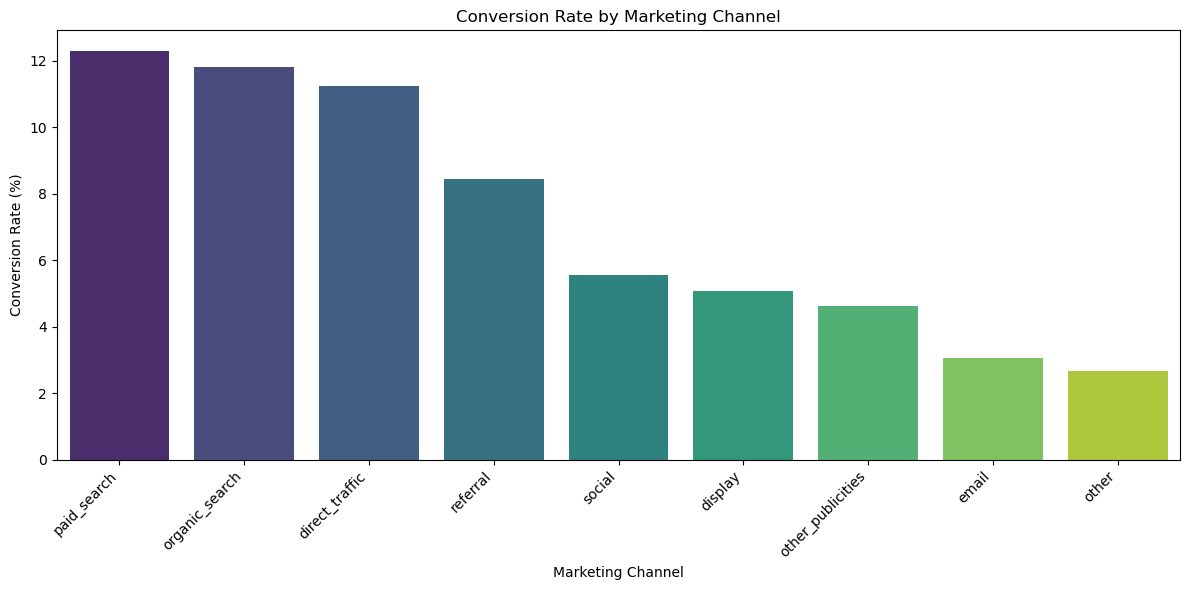

In [9]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=channel_plot.reset_index(),
    x="origin",
    y="conversion_rate",
    hue="origin",
    palette="viridis",
    legend=False
)

plt.title("Conversion Rate by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    "../dashboard/conversion_by_channel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
# Landing Page Performance Analysis

landing_analysis = (
    leads.groupby("landing_page_id")
    .agg(
        total_leads=("mql_id", "count"),
        converted_leads=("converted", "sum")
    )
)

landing_analysis["conversion_rate"] = (
    landing_analysis["converted_leads"]
    / landing_analysis["total_leads"] * 100
)

# Focus on landing pages with at least 20 leads
landing_filtered = landing_analysis[
    landing_analysis["total_leads"] >= 20
].copy()

# Top 10 landing pages by lead volume
top_landing_pages = landing_filtered.sort_values(
    by="total_leads",
    ascending=False
).head(10)

display(top_landing_pages.round(2))

,total_leads,converted_leads,conversion_rate
landing_page_id,,,
b76ef37428e6799c421989521c0e5077,912,171,18.75
22c29808c4f815213303f8933030604c,883,174,19.71
58326e62183c14b0c03085c33b9fdc44,495,27,5.45
88740e65d5d6b056e0cda098e1ea6313,445,31,6.97
ce1a65abd0973638f1c887a6efcfa82d,394,59,14.97
40dec9f3d5259a3d2dbcdab2114fae47,330,67,20.30
f017be4dbf86243af5c1ebed0cff36a2,310,21,6.77
e492ee5eaf1697716985cc6f33f9cd9b,291,10,3.44
a7982125ff7aa3b2054c6e44f9d28522,156,18,11.54


In [11]:
# Monthly Lead Conversion Analysis

leads["lead_month"] = (
    leads["first_contact_date"].dt.to_period("M")
)

monthly_analysis = (
    leads.groupby("lead_month")
    .agg(
        total_leads=("mql_id", "count"),
        converted_leads=("converted", "sum")
    )
)

monthly_analysis["conversion_rate"] = (
    monthly_analysis["converted_leads"]
    / monthly_analysis["total_leads"] * 100
)

display(monthly_analysis.round(2))

,total_leads,converted_leads,conversion_rate
lead_month,,,
2017-06,4,0,0.00
2017-07,239,2,0.84
2017-08,386,9,2.33
2017-09,312,7,2.24
2017-10,416,14,3.37
2017-11,445,18,4.04
2017-12,200,11,5.50
2018-01,1141,152,13.32
2018-02,1028,149,14.49


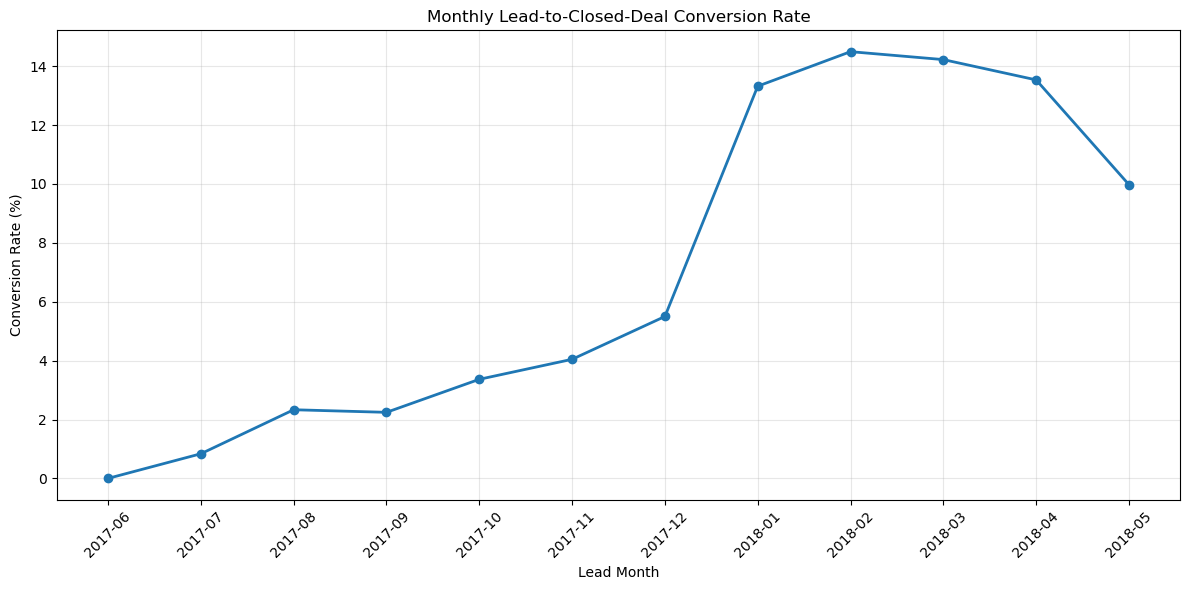

In [12]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_analysis.index.astype(str),
    monthly_analysis["conversion_rate"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Lead-to-Closed-Deal Conversion Rate")
plt.xlabel("Lead Month")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../dashboard/monthly_conversion_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
# Check whether every closed deal belongs to the leads dataset

matched_deals = deals["mql_id"].isin(leads["mql_id"]).sum()
unmatched_deals = (~deals["mql_id"].isin(leads["mql_id"])).sum()

print("Total Closed Deals:", len(deals))
print("Matched Deals:", matched_deals)
print("Unmatched Deals:", unmatched_deals)

print("Match Percentage:", round(matched_deals / len(deals) * 100, 2), "%")

Total Closed Deals: 842
Matched Deals: 842
Unmatched Deals: 0
Match Percentage: 100.0 %


In [14]:
# Analyze business segments among closed deals

segment_analysis = (
    deals.groupby("business_segment", dropna=False)
    .agg(
        closed_deals=("mql_id", "count")
    )
    .sort_values(by="closed_deals", ascending=False)
)

segment_analysis["deal_percentage"] = (
    segment_analysis["closed_deals"]
    / len(deals) * 100
)

display(segment_analysis.round(2))

,closed_deals,deal_percentage
business_segment,,
home_decor,105,12.47
health_beauty,93,11.05
car_accessories,77,9.14
household_utilities,71,8.43
construction_tools_house_garden,69,8.19
audio_video_electronics,64,7.60
computers,34,4.04
pet,30,3.56
food_supplement,28,3.33


In [15]:
# Analyze lead types among closed deals

lead_type_analysis = (
    deals.groupby("lead_type", dropna=False)
    .agg(
        closed_deals=("mql_id", "count")
    )
    .sort_values(by="closed_deals", ascending=False)
)

lead_type_analysis["deal_percentage"] = (
    lead_type_analysis["closed_deals"] / len(deals) * 100
)

display(lead_type_analysis.round(2))

,closed_deals,deal_percentage
lead_type,,
online_medium,332,39.43
online_big,126,14.96
industry,123,14.61
offline,104,12.35
online_small,77,9.14
online_beginner,57,6.77
online_top,14,1.66
NaN,6,0.71
other,3,0.36


In [16]:
# Analyze lead behaviour profiles among closed deals

behaviour_analysis = (
    deals.groupby("lead_behaviour_profile", dropna=False)
    .agg(
        closed_deals=("mql_id", "count")
    )
    .sort_values(by="closed_deals", ascending=False)
)

behaviour_analysis["deal_percentage"] = (
    behaviour_analysis["closed_deals"] / len(deals) * 100
)

display(behaviour_analysis.round(2))

,closed_deals,deal_percentage
lead_behaviour_profile,,
cat,407,48.34
NaN,177,21.02
eagle,123,14.61
wolf,95,11.28
shark,24,2.85
"cat, wolf",8,0.95
"eagle, wolf",3,0.36
"eagle, cat",3,0.36
"shark, wolf",1,0.12


In [17]:
# Calculate time taken to close each deal

deal_timing = leads[["mql_id", "first_contact_date"]].merge(
    deals[["mql_id", "won_date"]],
    on="mql_id",
    how="inner"
)

deal_timing["days_to_close"] = (
    deal_timing["won_date"] - deal_timing["first_contact_date"]
).dt.days

print("Total matched deals:", len(deal_timing))
print("\nDays to Close Summary:")
display(deal_timing["days_to_close"].describe().round(2))

print(
    "\nDeals with negative closing days:",
    (deal_timing["days_to_close"] < 0).sum()
)

Total matched deals: 842

Days to Close Summary:


count    842.00
mean      48.44
std       75.33
min       -2.00
25%        5.00
50%       14.00
75%       54.75
max      427.00
Name: days_to_close, dtype: float64


Deals with negative closing days: 1


In [18]:
# Find deals where won_date is before first_contact_date

negative_deals = deal_timing[
    deal_timing["days_to_close"] < 0
]

display(negative_deals)

,mql_id,first_contact_date,won_date,days_to_close
667,b91cf8812365f50ff4bda4bcd6206b05,2018-03-08,2018-03-06 19:38:55,-2


In [19]:
# Exclude negative closing durations only for timing analysis

valid_deal_timing = deal_timing[
    deal_timing["days_to_close"] >= 0
].copy()

print("Valid deals for timing analysis:", len(valid_deal_timing))
print("Excluded date anomalies:", len(deal_timing) - len(valid_deal_timing))

print("\nUpdated Days to Close Summary:")
display(valid_deal_timing["days_to_close"].describe().round(2))

Valid deals for timing analysis: 841
Excluded date anomalies: 1

Updated Days to Close Summary:


count    841.00
mean      48.50
std       75.35
min        0.00
25%        5.00
50%       14.00
75%       55.00
max      427.00
Name: days_to_close, dtype: float64

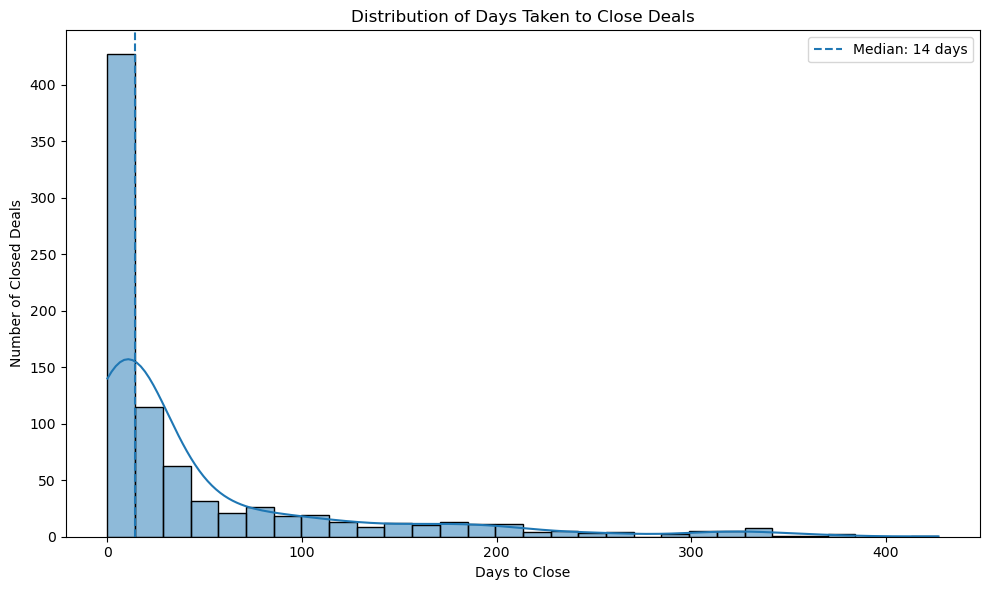

In [20]:
plt.figure(figsize=(10, 6))

sns.histplot(
    valid_deal_timing["days_to_close"],
    bins=30,
    kde=True
)

plt.axvline(
    valid_deal_timing["days_to_close"].median(),
    linestyle="--",
    label="Median: 14 days"
)

plt.title("Distribution of Days Taken to Close Deals")
plt.xlabel("Days to Close")
plt.ylabel("Number of Closed Deals")
plt.legend()
plt.tight_layout()

plt.savefig(
    "../dashboard/deal_closing_time_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
# Merge lead type with valid deal closing time

timing_by_type = valid_deal_timing.merge(
    deals[["mql_id", "lead_type"]],
    on="mql_id",
    how="left"
)

lead_type_timing = (
    timing_by_type.groupby("lead_type", dropna=False)
    .agg(
        total_deals=("mql_id", "count"),
        average_days=("days_to_close", "mean"),
        median_days=("days_to_close", "median")
    )
    .sort_values(by="median_days")
)

display(lead_type_timing.round(2))

,total_deals,average_days,median_days
lead_type,,,
online_top,14,21.43,6.0
online_medium,332,44.79,12.0
online_big,125,53.64,13.0
online_beginner,57,51.25,13.0
industry,123,46.50,15.0
offline,104,46.91,16.0
online_small,77,57.09,17.0
NaN,6,39.50,27.0
other,3,253.67,260.0


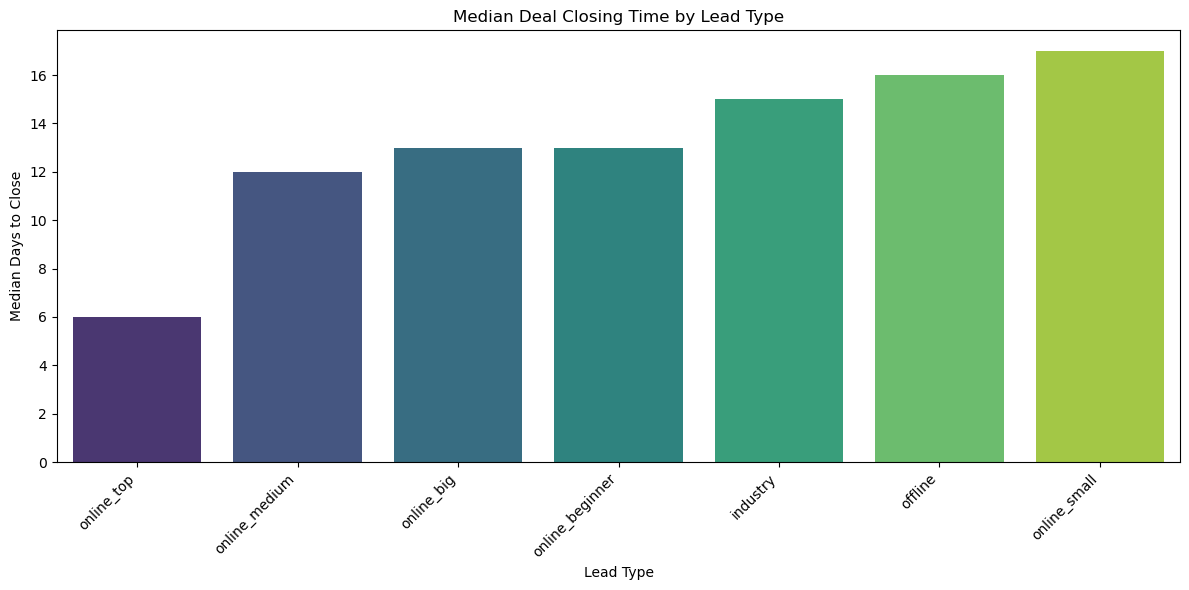

In [22]:
# Median closing time by lead type

plot_timing = lead_type_timing.dropna().drop(index="other", errors="ignore")

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_timing.reset_index(),
    x="lead_type",
    y="median_days",
    hue="lead_type",
    palette="viridis",
    legend=False
)

plt.title("Median Deal Closing Time by Lead Type")
plt.xlabel("Lead Type")
plt.ylabel("Median Days to Close")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    "../dashboard/closing_time_by_lead_type.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
# Analyze business types among closed deals

business_type_analysis = (
    deals.groupby("business_type", dropna=False)
    .agg(
        closed_deals=("mql_id", "count")
    )
    .sort_values(by="closed_deals", ascending=False)
)

business_type_analysis["deal_percentage"] = (
    business_type_analysis["closed_deals"] / len(deals) * 100
)

display(business_type_analysis.round(2))

,closed_deals,deal_percentage
business_type,,
reseller,587,69.71
manufacturer,242,28.74
NaN,10,1.19
other,3,0.36


In [24]:
# Analyze declared monthly revenue among closed deals

print("Declared Monthly Revenue Summary:")

display(
    deals["declared_monthly_revenue"]
    .describe()
    .round(2)
)

print(
    "\nZero Revenue Records:",
    (deals["declared_monthly_revenue"] == 0).sum()
)

print(
    "Missing Revenue Records:",
    deals["declared_monthly_revenue"].isna().sum()
)

Declared Monthly Revenue Summary:


count         842.00
mean        73377.68
std       1744799.18
min             0.00
25%             0.00
50%             0.00
75%             0.00
max      50000000.00
Name: declared_monthly_revenue, dtype: float64


Zero Revenue Records: 797
Missing Revenue Records: 0


In [25]:
# Analyze only positive declared monthly revenue

positive_revenue = deals[
    deals["declared_monthly_revenue"] > 0
]["declared_monthly_revenue"]

print("Businesses with Positive Declared Revenue:", len(positive_revenue))

print("\nPositive Revenue Summary:")
display(positive_revenue.describe().round(2))

print("\nTop 10 Highest Declared Monthly Revenues:")
display(
    positive_revenue.sort_values(ascending=False)
    .head(10)
    .reset_index(drop=True)
)

Businesses with Positive Declared Revenue: 45

Positive Revenue Summary:


count          45.00
mean      1372977.91
std       7507544.87
min             6.00
25%         15000.00
50%         50000.00
75%        130000.00
max      50000000.00
Name: declared_monthly_revenue, dtype: float64


Top 10 Highest Declared Monthly Revenues:


0    50000000.0
1     8000000.0
2      500000.0
3      300000.0
4      300000.0
5      250000.0
6      250000.0
7      210000.0
8      200000.0
9      180000.0
Name: declared_monthly_revenue, dtype: float64

In [26]:
# Inspect businesses with declared monthly revenue >= 100,000

high_revenue_businesses = (
    deals[deals["declared_monthly_revenue"] >= 100000]
    [
        [
            "mql_id",
            "business_segment",
            "business_type",
            "lead_type",
            "declared_monthly_revenue"
        ]
    ]
    .sort_values(
        by="declared_monthly_revenue",
        ascending=False
    )
)

display(high_revenue_businesses)

,mql_id,business_segment,business_type,lead_type,declared_monthly_revenue
188,6a10f542e6f79265c34a405dbc928e37,construction_tools_house_garden,manufacturer,industry,50000000.0
408,50523d9bd9d5d9a44bbc2f778954c5ae,phone_mobile,reseller,online_big,8000000.0
681,9dde4d7713ae64986ab6f5c9f9cf94d3,other,other,other,500000.0
605,b39ac02ff5021fed10cb9988a23d5d02,home_decor,manufacturer,online_small,300000.0
589,30c1778642a506dbd803a0fa5ece533e,pet,reseller,industry,300000.0
392,010ed37e44e2fdc175b4c5c6c930805a,audio_video_electronics,reseller,online_medium,250000.0
813,3223fed48f30bbdc0f6040b466516bcb,construction_tools_house_garden,manufacturer,online_big,250000.0
236,6d78dcbeb39103c047f486abd2519ee4,health_beauty,reseller,online_small,210000.0
838,8723201570415eb23b4f095d8c20a27c,construction_tools_house_garden,reseller,online_big,200000.0
59,a55b94066766f2d29fc22a3bb52d78f6,toys,reseller,online_big,180000.0


In [27]:
# Analyze positive declared revenue by business segment

positive_deals = deals[
    deals["declared_monthly_revenue"] > 0
].copy()

revenue_by_segment = (
    positive_deals.groupby("business_segment", dropna=False)
    .agg(
        businesses=("mql_id", "count"),
        total_declared_revenue=("declared_monthly_revenue", "sum"),
        average_revenue=("declared_monthly_revenue", "mean"),
        median_revenue=("declared_monthly_revenue", "median")
    )
    .sort_values(
        by="total_declared_revenue",
        ascending=False
    )
)

display(revenue_by_segment.round(2))

,businesses,total_declared_revenue,average_revenue,median_revenue
business_segment,,,,
construction_tools_house_garden,7,50695006.0,7242143.71,130000.0
phone_mobile,1,8000000.0,8000000.00,8000000.0
home_decor,6,710000.0,118333.33,100000.0
other,3,626000.0,208666.67,120000.0
pet,1,300000.0,300000.00,300000.0
health_beauty,5,295000.0,59000.00,25000.0
audio_video_electronics,2,270000.0,135000.00,135000.0
toys,4,259000.0,64750.00,37500.0
car_accessories,4,185000.0,46250.00,37500.0


In [28]:
# Positive declared revenue by business type

revenue_by_business_type = (
    positive_deals.groupby("business_type", dropna=False)
    .agg(
        businesses=("mql_id", "count"),
        total_declared_revenue=("declared_monthly_revenue", "sum"),
        average_revenue=("declared_monthly_revenue", "mean"),
        median_revenue=("declared_monthly_revenue", "median")
    )
    .sort_values(
        by="total_declared_revenue",
        ascending=False
    )
)

display(revenue_by_business_type.round(2))

,businesses,total_declared_revenue,average_revenue,median_revenue
business_type,,,,
manufacturer,7,50825000.0,7260714.29,120000.0
reseller,35,10333006.0,295228.74,30000.0
other,3,626000.0,208666.67,120000.0


In [29]:
# Analyze company and GTIN information

company_gtin_analysis = pd.DataFrame({
    "Metric": [
        "Company information available",
        "Company information missing",
        "GTIN information available",
        "GTIN information missing"
    ],
    "Count": [
        deals["has_company"].notna().sum(),
        deals["has_company"].isna().sum(),
        deals["has_gtin"].notna().sum(),
        deals["has_gtin"].isna().sum()
    ]
})

company_gtin_analysis["Percentage"] = (
    company_gtin_analysis["Count"] / len(deals) * 100
)

display(company_gtin_analysis.round(2))

,Metric,Count,Percentage
0,Company information available,63,7.48
1,Company information missing,779,92.52
2,GTIN information available,64,7.60
3,GTIN information missing,778,92.40


In [30]:
# Check actual values in company and GTIN columns

print("Company Values:")
print(deals["has_company"].value_counts(dropna=False))

print("\nGTIN Values:")
print(deals["has_gtin"].value_counts(dropna=False))

Company Values:
has_company
NaN      779
True      58
False      5
Name: count, dtype: int64

GTIN Values:
has_gtin
NaN      778
True      54
False     10
Name: count, dtype: int64


In [31]:
# Analyze average stock and declared product catalog size

print("AVERAGE STOCK SUMMARY")
display(deals["average_stock"].describe().round(2))

print("\nPRODUCT CATALOG SIZE SUMMARY")
display(deals["declared_product_catalog_size"].describe().round(2))

print("\nMissing Values:")
print("Average Stock:", deals["average_stock"].isna().sum())
print("Product Catalog Size:", deals["declared_product_catalog_size"].isna().sum())

AVERAGE STOCK SUMMARY


count       66
unique       6
top       5-20
freq        22
Name: average_stock, dtype: object


PRODUCT CATALOG SIZE SUMMARY


count      69.00
mean      233.03
std       352.38
min         1.00
25%        30.00
50%       100.00
75%       300.00
max      2000.00
Name: declared_product_catalog_size, dtype: float64


Missing Values:
Average Stock: 776
Product Catalog Size: 773


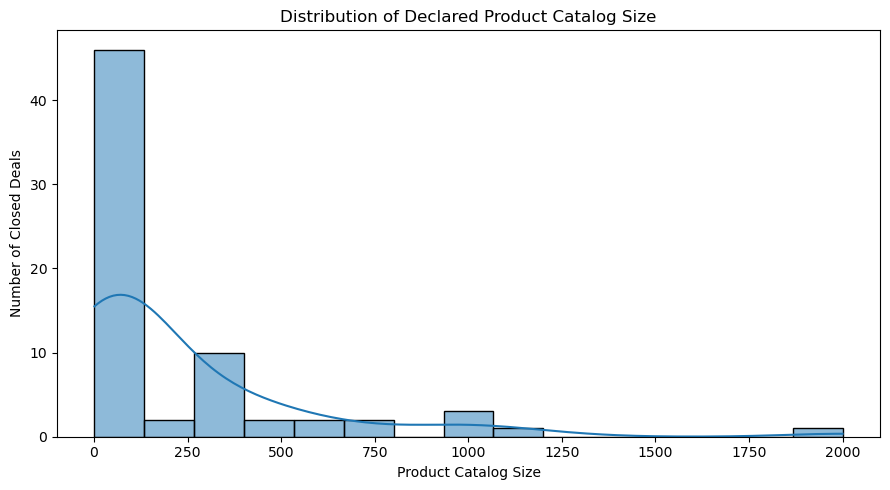

In [32]:
plt.figure(figsize=(9, 5))

sns.histplot(
    deals["declared_product_catalog_size"].dropna(),
    bins=15,
    kde=True
)

plt.title("Distribution of Declared Product Catalog Size")
plt.xlabel("Product Catalog Size")
plt.ylabel("Number of Closed Deals")

plt.tight_layout()
plt.savefig(
    "../dashboard/product_catalog_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [33]:
# Average stock category distribution

stock_analysis = (
    deals["average_stock"]
    .value_counts(dropna=False)
    .reset_index()
)

stock_analysis.columns = ["Average Stock Range", "Business Count"]

stock_analysis["Percentage"] = (
    stock_analysis["Business Count"] / len(deals) * 100
)

display(stock_analysis.round(2))

,Average Stock Range,Business Count,Percentage
0,NaN,776,92.16
1,5-20,22,2.61
2,50-200,15,1.78
3,1-5,10,1.19
4,20-50,8,0.95
5,200+,7,0.83
6,unknown,4,0.48


In [34]:
# Product catalog size categories

catalog_data = deals["declared_product_catalog_size"].dropna()

catalog_categories = pd.cut(
    catalog_data,
    bins=[0, 50, 100, 500, float("inf")],
    labels=["1-50", "51-100", "101-500", "500+"]
)

catalog_analysis = (
    catalog_categories
    .value_counts()
    .sort_index()
    .reset_index()
)

catalog_analysis.columns = ["Catalog Size Range", "Business Count"]

catalog_analysis["Percentage"] = (
    catalog_analysis["Business Count"] / len(catalog_data) * 100
)

display(catalog_analysis.round(2))

,Catalog Size Range,Business Count,Percentage
0,1-50,29,42.03
1,51-100,14,20.29
2,101-500,17,24.64
3,500+,9,13.04


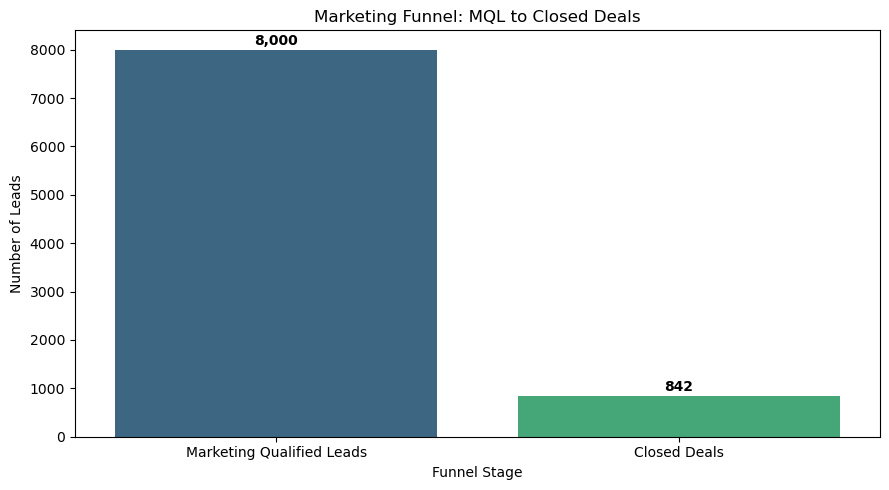

Overall Conversion Rate: 10.53 %


In [35]:
# Marketing Funnel Visualization

funnel_stages = ["Marketing Qualified Leads", "Closed Deals"]
funnel_values = [len(leads), len(deals)]

plt.figure(figsize=(9, 5))

sns.barplot(
    x=funnel_stages,
    y=funnel_values,
    hue=funnel_stages,
    palette="viridis",
    legend=False
)

for i, value in enumerate(funnel_values):
    plt.text(i, value + 100, f"{value:,}", ha="center", fontweight="bold")

plt.title("Marketing Funnel: MQL to Closed Deals")
plt.ylabel("Number of Leads")
plt.xlabel("Funnel Stage")

plt.tight_layout()
plt.savefig(
    "../dashboard/marketing_funnel_overview.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Overall Conversion Rate:", round(len(deals) / len(leads) * 100, 2), "%")

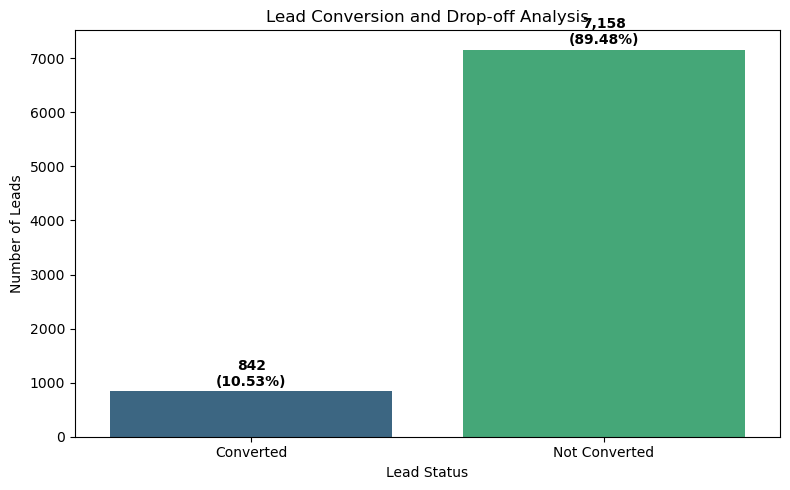

In [36]:
# Conversion and Drop-off Analysis

converted_count = leads["converted"].sum()
not_converted_count = len(leads) - converted_count

conversion_data = pd.DataFrame({
    "Lead Status": ["Converted", "Not Converted"],
    "Count": [converted_count, not_converted_count]
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=conversion_data,
    x="Lead Status",
    y="Count",
    hue="Lead Status",
    palette="viridis",
    legend=False
)

for i, row in conversion_data.iterrows():
    percentage = row["Count"] / len(leads) * 100
    plt.text(
        i,
        row["Count"] + 100,
        f'{row["Count"]:,}\n({percentage:.2f}%)',
        ha="center",
        fontweight="bold"
    )

plt.title("Lead Conversion and Drop-off Analysis")
plt.ylabel("Number of Leads")
plt.xlabel("Lead Status")

plt.tight_layout()
plt.savefig(
    "../dashboard/conversion_dropoff_analysis.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [37]:
# Include missing marketing origins

leads["origin_clean"] = leads["origin"].fillna("missing_unspecified")

final_channel_analysis = (
    leads.groupby("origin_clean")
    .agg(
        total_leads=("mql_id", "count"),
        converted_leads=("converted", "sum")
    )
)

final_channel_analysis["conversion_rate"] = (
    final_channel_analysis["converted_leads"]
    / final_channel_analysis["total_leads"] * 100
)

final_channel_analysis["drop_off"] = (
    final_channel_analysis["total_leads"]
    - final_channel_analysis["converted_leads"]
)

final_channel_analysis = final_channel_analysis.sort_values(
    "conversion_rate", ascending=False
)

display(final_channel_analysis.round(2))

print("Total Leads:", final_channel_analysis["total_leads"].sum())
print("Total Converted:", final_channel_analysis["converted_leads"].sum())

,total_leads,converted_leads,conversion_rate,drop_off
origin_clean,,,,
missing_unspecified,60,14,23.33,46
unknown,1099,179,16.29,920
paid_search,1586,195,12.30,1391
organic_search,2296,271,11.80,2025
direct_traffic,499,56,11.22,443
referral,284,24,8.45,260
social,1350,75,5.56,1275
display,118,6,5.08,112
other_publicities,65,3,4.62,62


Total Leads: 8000
Total Converted: 842


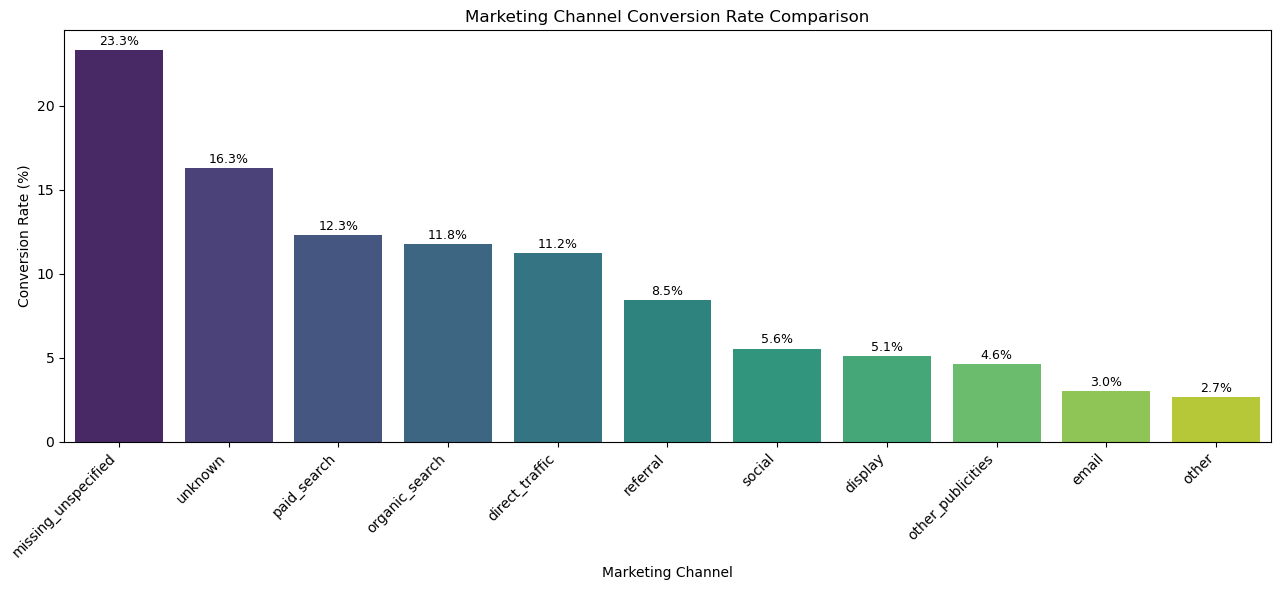

Chart saved successfully!


In [38]:
# Final Marketing Channel Performance Chart

channel_chart = final_channel_analysis.reset_index()

plt.figure(figsize=(13, 6))

sns.barplot(
    data=channel_chart,
    x="origin_clean",
    y="conversion_rate",
    hue="origin_clean",
    palette="viridis",
    legend=False
)

for i, row in channel_chart.iterrows():
    plt.text(
        i,
        row["conversion_rate"] + 0.3,
        f'{row["conversion_rate"]:.1f}%',
        ha="center",
        fontsize=9
    )

plt.title("Marketing Channel Conversion Rate Comparison")
plt.xlabel("Marketing Channel")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.savefig(
    "../dashboard/final_channel_conversion.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Chart saved successfully!")

In [39]:
# Marketing Funnel KPI Summary

total_leads = len(leads)
converted_leads = int(leads["converted"].sum())
not_converted_leads = total_leads - converted_leads

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Marketing Qualified Leads",
        "Total Closed Deals",
        "Leads Not Converted",
        "Lead-to-Closed-Deal Conversion Rate",
        "Lead Drop-off Rate",
        "Median Days to Close"
    ],
    "Value": [
        total_leads,
        converted_leads,
        not_converted_leads,
        round(converted_leads / total_leads * 100, 2),
        round(not_converted_leads / total_leads * 100, 2),
        round(valid_deal_timing["days_to_close"].median(), 2)
    ]
})

display(kpi_summary)

kpi_summary.to_csv(
    "../dashboard/marketing_funnel_kpis.csv",
    index=False
)

print("KPI summary saved successfully!")

,KPI,Value
0,Total Marketing Qualified Leads,8000.00
1,Total Closed Deals,842.00
2,Leads Not Converted,7158.00
3,Lead-to-Closed-Deal Conversion Rate,10.53
4,Lead Drop-off Rate,89.48
5,Median Days to Close,14.00


KPI summary saved successfully!


In [40]:
# Save final marketing channel analysis

final_channel_analysis.to_csv(
    "../reports/marketing_channel_analysis.csv"
)

print("Marketing channel analysis exported successfully!")
print("File: marketing_channel_analysis.csv")

Marketing channel analysis exported successfully!
File: marketing_channel_analysis.csv


In [41]:
# Export landing page performance analysis

top_landing_pages.to_csv(
    "../reports/landing_page_performance.csv"
)

print("Landing page analysis exported successfully!")
print("File: landing_page_performance.csv")
print("Total landing pages analyzed:", len(top_landing_pages))

Landing page analysis exported successfully!
File: landing_page_performance.csv
Total landing pages analyzed: 10


In [42]:
# Export monthly lead conversion analysis

monthly_analysis.to_csv(
    "../reports/monthly_conversion_analysis.csv",
    index=True
)

print("Monthly conversion analysis exported successfully!")
print("File: monthly_conversion_analysis.csv")
print("Months analyzed:", len(monthly_analysis))

Monthly conversion analysis exported successfully!
File: monthly_conversion_analysis.csv
Months analyzed: 12


In [43]:
# Export deal closing time analysis

valid_deal_timing.to_csv(
    "../reports/deal_closing_time_analysis.csv",
    index=False
)

print("Deal closing time analysis exported successfully!")
print("File: deal_closing_time_analysis.csv")

print("\nClosing Time Summary:")
display(
    valid_deal_timing["days_to_close"]
    .describe()
    .round(2)
)

Deal closing time analysis exported successfully!
File: deal_closing_time_analysis.csv

Closing Time Summary:


count    841.00
mean      48.50
std       75.35
min        0.00
25%        5.00
50%       14.00
75%       55.00
max      427.00
Name: days_to_close, dtype: float64

In [44]:
# Export business segment analysis

segment_analysis.to_csv(
    "../reports/business_segment_analysis.csv"
)

print("Business segment analysis exported successfully!")
print("File: business_segment_analysis.csv")
print("Segments analyzed:", len(segment_analysis))

Business segment analysis exported successfully!
File: business_segment_analysis.csv
Segments analyzed: 34


In [45]:
# Lead Type Analysis

lead_type_analysis = (
    deals.groupby("lead_type", dropna=False)
    .agg(closed_deals=("mql_id", "count"))
    .sort_values(by="closed_deals", ascending=False)
)

lead_type_analysis["percentage"] = (
    lead_type_analysis["closed_deals"] / len(deals) * 100
)

display(lead_type_analysis.round(2))

lead_type_analysis.to_csv(
    "../reports/lead_type_analysis.csv"
)

print("Lead type analysis exported successfully!")

,closed_deals,percentage
lead_type,,
online_medium,332,39.43
online_big,126,14.96
industry,123,14.61
offline,104,12.35
online_small,77,9.14
online_beginner,57,6.77
online_top,14,1.66
NaN,6,0.71
other,3,0.36


Lead type analysis exported successfully!


In [46]:
# Business Type Analysis

business_type_analysis = (
    deals.groupby("business_type", dropna=False)
    .agg(closed_deals=("mql_id", "count"))
    .sort_values(by="closed_deals", ascending=False)
)

business_type_analysis["percentage"] = (
    business_type_analysis["closed_deals"] / len(deals) * 100
)

display(business_type_analysis.round(2))

business_type_analysis.to_csv(
    "../reports/business_type_analysis.csv"
)

print("Business type analysis exported successfully!")

,closed_deals,percentage
business_type,,
reseller,587,69.71
manufacturer,242,28.74
NaN,10,1.19
other,3,0.36


Business type analysis exported successfully!


In [47]:
# Company and GTIN Data Quality Report

profile_quality = pd.DataFrame({
    "Metric": [
        "Company True",
        "Company False",
        "Company Missing",
        "GTIN True",
        "GTIN False",
        "GTIN Missing"
    ],
    "Count": [
        (deals["has_company"] == True).sum(),
        (deals["has_company"] == False).sum(),
        deals["has_company"].isna().sum(),
        (deals["has_gtin"] == True).sum(),
        (deals["has_gtin"] == False).sum(),
        deals["has_gtin"].isna().sum()
    ]
})

profile_quality["Percentage"] = (
    profile_quality["Count"] / len(deals) * 100
)

display(profile_quality.round(2))

profile_quality.to_csv(
    "../reports/business_profile_data_quality.csv",
    index=False
)

print("Business profile data quality report exported successfully!")

,Metric,Count,Percentage
0,Company True,58,6.89
1,Company False,5,0.59
2,Company Missing,779,92.52
3,GTIN True,54,6.41
4,GTIN False,10,1.19
5,GTIN Missing,778,92.40


Business profile data quality report exported successfully!


In [48]:
# Business Readiness Data Analysis

stock_summary = deals["average_stock"].value_counts(dropna=False)

catalog_summary = catalog_categories.value_counts().sort_index()

print("STOCK DISTRIBUTION")
display(stock_summary)

print("\nCATALOG SIZE DISTRIBUTION")
display(catalog_summary)

# Save catalog and stock analysis separately
stock_summary.to_csv(
    "../reports/average_stock_distribution.csv"
)

catalog_summary.to_csv(
    "../reports/catalog_size_distribution.csv"
)

print("\nBusiness readiness reports exported successfully!")

STOCK DISTRIBUTION


average_stock
NaN        776
5-20        22
50-200      15
1-5         10
20-50        8
200+         7
unknown      4
Name: count, dtype: int64


CATALOG SIZE DISTRIBUTION


declared_product_catalog_size
1-50       29
51-100     14
101-500    17
500+        9
Name: count, dtype: int64


Business readiness reports exported successfully!


In [49]:
# Marketing Funnel Business Recommendations

recommendations = pd.DataFrame({
    "Area": [
        "Paid Search",
        "Organic Search",
        "Social Media",
        "Email Marketing",
        "Lead Follow-up",
        "Landing Pages",
        "Data Quality",
        "Lead Qualification"
    ],
    "Finding": [
        "12.30% conversion rate",
        "11.80% conversion rate",
        "5.56% conversion rate",
        "3.04% conversion rate",
        "Median closing time is 14 days",
        "Some high-volume pages have low conversion",
        "Over 92% missing company and GTIN data",
        "Stock and catalog information is mostly missing"
    ],
    "Recommendation": [
        "Optimize paid campaigns and target high-intent keywords.",
        "Invest in SEO and high-performing organic content.",
        "Test new creatives, audiences and campaign messages.",
        "Improve email personalization and calls to action.",
        "Introduce structured follow-ups around the 14-day checkpoint.",
        "Review low-converting pages and improve their content and CTAs.",
        "Improve source and business-profile data collection.",
        "Collect stock and catalog information during lead qualification."
    ]
})

display(recommendations)

recommendations.to_csv(
    "../reports/business_recommendations.csv",
    index=False
)

print("Business recommendations exported successfully!")

,Area,Finding,Recommendation
0,Paid Search,12.30% conversion rate,Optimize paid campaigns and target high-intent...
1,Organic Search,11.80% conversion rate,Invest in SEO and high-performing organic cont...
2,Social Media,5.56% conversion rate,"Test new creatives, audiences and campaign mes..."
3,Email Marketing,3.04% conversion rate,Improve email personalization and calls to act...
4,Lead Follow-up,Median closing time is 14 days,Introduce structured follow-ups around the 14-...
5,Landing Pages,Some high-volume pages have low conversion,Review low-converting pages and improve their ...
6,Data Quality,Over 92% missing company and GTIN data,Improve source and business-profile data colle...
7,Lead Qualification,Stock and catalog information is mostly missing,Collect stock and catalog information during l...


Business recommendations exported successfully!


In [53]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import os

os.makedirs("../dashboard", exist_ok=True)

channel_data = final_channel_analysis.reset_index()
monthly_data = monthly_analysis.reset_index()
landing_data = top_landing_pages.reset_index()

# Create dashboard with correct subplot types
fig = make_subplots(
    rows=3,
    cols=2,
    specs=[
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "domain"}]
    ],
    subplot_titles=(
        "Marketing Funnel",
        "Conversion Rate by Channel",
        "Monthly Conversion Trend",
        "Top 10 Landing Pages",
        "Days to Close Distribution",
        "Lead Conversion Overview"
    ),
    vertical_spacing=0.12,
    horizontal_spacing=0.12
)

# 1. Marketing Funnel
fig.add_trace(
    go.Bar(
        x=["Qualified Leads", "Closed Deals"],
        y=[len(leads), len(deals)],
        text=[f"{len(leads):,}", f"{len(deals):,}"],
        textposition="auto",
        name="Funnel"
    ),
    row=1, col=1
)

# 2. Channel Conversion
fig.add_trace(
    go.Bar(
        x=channel_data["origin_clean"],
        y=channel_data["conversion_rate"],
        name="Channel Conversion"
    ),
    row=1, col=2
)

# 3. Monthly Conversion
fig.add_trace(
    go.Scatter(
        x=monthly_data.iloc[:, 0],
        y=monthly_data["conversion_rate"],
        mode="lines+markers",
        name="Monthly Conversion"
    ),
    row=2, col=1
)

# 4. Landing Page Performance
fig.add_trace(
    go.Bar(
        x=landing_data["landing_page_id"],
        y=landing_data["conversion_rate"],
        name="Landing Page Conversion"
    ),
    row=2, col=2
)

# 5. Closing Time Distribution
fig.add_trace(
    go.Histogram(
        x=valid_deal_timing["days_to_close"],
        nbinsx=30,
        name="Days to Close"
    ),
    row=3, col=1
)

# 6. Lead Conversion Pie Chart
fig.add_trace(
    go.Pie(
        labels=["Converted", "Not Converted"],
        values=[
            int(leads["converted"].sum()),
            int((~leads["converted"]).sum())
        ],
        hole=0.55,
        name="Lead Status"
    ),
    row=3, col=2
)

# Dashboard formatting
fig.update_layout(
    title={
        "text": "MARKETING FUNNEL & CONVERSION PERFORMANCE DASHBOARD",
        "x": 0.5,
        "xanchor": "center"
    },
    height=1100,
    width=1500,
    template="plotly_white",
    showlegend=False
)

fig.update_yaxes(title_text="Number of Leads", row=1, col=1)
fig.update_yaxes(title_text="Conversion Rate (%)", row=1, col=2)
fig.update_yaxes(title_text="Conversion Rate (%)", row=2, col=1)
fig.update_yaxes(title_text="Conversion Rate (%)", row=2, col=2)
fig.update_yaxes(title_text="Number of Deals", row=3, col=1)

# Export dashboard
dashboard_file = "../dashboard/Marketing_Funnel_Interactive_Dashboard.html"

fig.write_html(
    dashboard_file,
    include_plotlyjs=True,
    full_html=True
)

print("=" * 50)
print("INTERACTIVE DASHBOARD EXPORT")
print("=" * 50)
print("Dashboard saved successfully!")
print("File:", dashboard_file)
print("File exists:", os.path.exists(dashboard_file))

TypeError: Type is not JSON serializable: Period

In [54]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import os

os.makedirs("../dashboard", exist_ok=True)

channel_data = final_channel_analysis.reset_index()
monthly_data = monthly_analysis.reset_index()
landing_data = top_landing_pages.reset_index()

# Create dashboard with correct subplot types
fig = make_subplots(
    rows=3,
    cols=2,
    specs=[
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "domain"}]
    ],
    subplot_titles=(
        "Marketing Funnel",
        "Conversion Rate by Channel",
        "Monthly Conversion Trend",
        "Top 10 Landing Pages",
        "Days to Close Distribution",
        "Lead Conversion Overview"
    ),
    vertical_spacing=0.12,
    horizontal_spacing=0.12
)

# 1. Marketing Funnel
fig.add_trace(
    go.Bar(
        x=["Qualified Leads", "Closed Deals"],
        y=[len(leads), len(deals)],
        text=[f"{len(leads):,}", f"{len(deals):,}"],
        textposition="auto",
        name="Funnel"
    ),
    row=1, col=1
)

# 2. Channel Conversion
fig.add_trace(
    go.Bar(
        x=channel_data["origin_clean"],
        y=channel_data["conversion_rate"],
        name="Channel Conversion"
    ),
    row=1, col=2
)

# 3. Monthly Conversion
fig.add_trace(
    go.Scatter(
        x=monthly_data.iloc[:, 0],
        y=monthly_data["conversion_rate"],
        mode="lines+markers",
        name="Monthly Conversion"
    ),
    row=2, col=1
)

# 4. Landing Page Performance
fig.add_trace(
    go.Bar(
        x=landing_data["landing_page_id"],
        y=landing_data["conversion_rate"],
        name="Landing Page Conversion"
    ),
    row=2, col=2
)

# 5. Closing Time Distribution
fig.add_trace(
    go.Histogram(
        x=valid_deal_timing["days_to_close"],
        nbinsx=30,
        name="Days to Close"
    ),
    row=3, col=1
)

# 6. Lead Conversion Pie Chart
fig.add_trace(
    go.Pie(
        labels=["Converted", "Not Converted"],
        values=[
            int(leads["converted"].sum()),
            int((~leads["converted"]).sum())
        ],
        hole=0.55,
        name="Lead Status"
    ),
    row=3, col=2
)

# Dashboard formatting
fig.update_layout(
    title={
        "text": "MARKETING FUNNEL & CONVERSION PERFORMANCE DASHBOARD",
        "x": 0.5,
        "xanchor": "center"
    },
    height=1100,
    width=1500,
    template="plotly_white",
    showlegend=False
)

fig.update_yaxes(title_text="Number of Leads", row=1, col=1)
fig.update_yaxes(title_text="Conversion Rate (%)", row=1, col=2)
fig.update_yaxes(title_text="Conversion Rate (%)", row=2, col=1)
fig.update_yaxes(title_text="Conversion Rate (%)", row=2, col=2)
fig.update_yaxes(title_text="Number of Deals", row=3, col=1)

# Export dashboard
dashboard_file = "../dashboard/Marketing_Funnel_Interactive_Dashboard.html"

fig.write_html(
    dashboard_file,
    include_plotlyjs=True,
    full_html=True
)

print("=" * 50)
print("INTERACTIVE DASHBOARD EXPORT")
print("=" * 50)
print("Dashboard saved successfully!")
print("File:", dashboard_file)
print("File exists:", os.path.exists(dashboard_file))

TypeError: Type is not JSON serializable: Period

In [52]:
# Re-export the existing dashboard

fig.write_html(
    "../dashboard/Marketing_Funnel_Interactive_Dashboard.html",
    include_plotlyjs=True,
    full_html=True
)

print("Dashboard exported successfully!")
print(
    "File exists:",
    os.path.exists("../dashboard/Marketing_Funnel_Interactive_Dashboard.html")
)

TypeError: Type is not JSON serializable: Period

In [55]:
import pandas as pd
import numpy as np
import os

# Function to convert Period values into strings
def clean_periods(obj):
    if isinstance(obj, pd.Period):
        return str(obj)

    elif isinstance(obj, np.ndarray):
        return [clean_periods(x) for x in obj]

    elif isinstance(obj, (list, tuple)):
        return [clean_periods(x) for x in obj]

    elif isinstance(obj, dict):
        return {k: clean_periods(v) for k, v in obj.items()}

    return obj


# Clean data in every chart trace
for trace in fig.data:
    for prop in ["x", "y", "labels", "values",
                 "text", "customdata", "hovertext"]:

        value = getattr(trace, prop, None)

        if value is not None:
            setattr(trace, prop, clean_periods(value))


# Export dashboard
dashboard_file = "../dashboard/Marketing_Funnel_Interactive_Dashboard.html"

fig.write_html(
    dashboard_file,
    include_plotlyjs=True,
    full_html=True
)

print("Dashboard exported successfully!")
print("File exists:", os.path.exists(dashboard_file))

Dashboard exported successfully!
File exists: True


In [56]:
import reportlab
import os

print("ReportLab version:", reportlab.Version)
print("Reports folder exists:", os.path.exists("../reports"))
print("Dashboard folder exists:", os.path.exists("../dashboard"))

ReportLab version: 5.1.0
Reports folder exists: True
Dashboard folder exists: True


In [57]:
import os
import pandas as pd
from datetime import datetime

from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER, TA_LEFT
from reportlab.lib.units import inch
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table,
    TableStyle, PageBreak, Image
)

# --------------------------------------------------
# 1. PDF FILE LOCATION
# --------------------------------------------------

os.makedirs("../reports", exist_ok=True)

pdf_file = "../reports/Marketing_Funnel_Analysis_Report.pdf"
full_path = os.path.abspath(pdf_file)
report_date = datetime.now().strftime("%d %B %Y")

# --------------------------------------------------
# 2. DOCUMENT AND STYLES
# --------------------------------------------------

doc = SimpleDocTemplate(
    pdf_file,
    pagesize=A4,
    rightMargin=40,
    leftMargin=40,
    topMargin=45,
    bottomMargin=45
)

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="MainTitle",
    parent=styles["Title"],
    fontSize=21,
    leading=27,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#17365D"),
    spaceAfter=12
))

styles.add(ParagraphStyle(
    name="SectionHeading",
    parent=styles["Heading2"],
    fontSize=14,
    leading=18,
    textColor=colors.HexColor("#17365D"),
    spaceBefore=12,
    spaceAfter=8
))

styles.add(ParagraphStyle(
    name="BodyCustom",
    parent=styles["BodyText"],
    fontSize=9,
    leading=14,
    spaceAfter=7
))

story = []

# --------------------------------------------------
# 3. HELPER FUNCTIONS
# --------------------------------------------------

def add_heading(text):
    story.append(Paragraph(text, styles["SectionHeading"]))

def add_paragraph(text):
    story.append(Paragraph(str(text), styles["BodyCustom"]))

def add_table(data, widths=None):
    table = Table(data, colWidths=widths, repeatRows=1)

    table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("FONTNAME", (0, 1), (-1, -1), "Helvetica"),
        ("FONTSIZE", (0, 0), (-1, -1), 8),
        ("GRID", (0, 0), (-1, -1), 0.4, colors.grey),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1),
         [colors.white, colors.HexColor("#EEF3F8")]),
        ("TOPPADDING", (0, 0), (-1, -1), 6),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 6),
    ]))

    story.append(table)
    story.append(Spacer(1, 10))


def add_chart(path, width=6.5*inch):
    if os.path.exists(path):
        img = Image(path)
        img.drawWidth = width
        img.drawHeight = width * img.imageHeight / img.imageWidth
        story.append(img)
        story.append(Spacer(1, 12))


# --------------------------------------------------
# 4. COVER AND PROJECT OVERVIEW
# --------------------------------------------------

story.append(Spacer(1, 35))

story.append(Paragraph(
    "MARKETING FUNNEL &<br/>CONVERSION PERFORMANCE ANALYSIS",
    styles["MainTitle"]
))

story.append(Paragraph(
    "Future Interns – Data Science & Analytics Internship | Task 3",
    styles["BodyCustom"]
))

story.append(Spacer(1, 15))

add_paragraph("<b>Prepared by:</b> Gonchala Lakshmi Padmaja")
add_paragraph(f"<b>Report Date:</b> {report_date}")
add_paragraph("<b>Dataset:</b> Olist Marketing Funnel Dataset")
add_paragraph(
    "<b>Dataset Source:</b> "
    "https://www.kaggle.com/datasets/olistbr/marketing-funnel-olist"
)

add_heading("1. Project Overview")

add_paragraph(
    "This project analyzes marketing qualified leads and closed deals "
    "to understand lead-to-customer conversion performance. It evaluates "
    "conversion drop-offs, marketing channel effectiveness, landing-page "
    "performance, monthly trends, and deal-closing time."
)

add_paragraph(
    "The analysis uses the MQL dataset and closed-deals dataset, "
    "connected through the common mql_id field."
)

# --------------------------------------------------
# 5. KEY PERFORMANCE INDICATORS
# --------------------------------------------------

add_heading("2. Key Performance Indicators")

kpi_data = [
    ["KPI", "Result"],
    ["Total Marketing Qualified Leads", "8,000"],
    ["Total Closed Deals", "842"],
    ["Leads Not Converted", "7,158"],
    ["Lead-to-Closed-Deal Conversion Rate", "10.53%"],
    ["Lead Drop-off Rate", "89.48%"],
    ["Median Days to Close", "14 days"]
]

add_table(kpi_data, [300, 150])

add_chart("../dashboard/marketing_funnel_overview.png")

# --------------------------------------------------
# 6. MARKETING CHANNEL ANALYSIS
# --------------------------------------------------

add_heading("3. Marketing Channel Performance")

channel_data = final_channel_analysis.reset_index()

channel_table = [
    ["Marketing Channel", "Leads", "Converted", "Conversion %"]
]

for _, row in channel_data.iterrows():
    channel_table.append([
        str(row.iloc[0]),
        f"{int(row['total_leads']):,}",
        f"{int(row['converted_leads']):,}",
        f"{row['conversion_rate']:.2f}%"
    ])

add_table(channel_table, [180, 90, 90, 90])

add_paragraph(
    "<b>Key finding:</b> Among identifiable marketing channels, "
    "paid search achieved a 12.30% conversion rate, followed by "
    "organic search at 11.80%. Social media recorded 5.56%, while "
    "email marketing recorded 3.04%."
)

add_paragraph(
    "The missing/unspecified origin category contains only 60 leads. "
    "Its 23.33% conversion rate should not be interpreted as a "
    "high-performing marketing channel."
)

add_chart("../dashboard/final_channel_conversion.png")

# --------------------------------------------------
# 7. LANDING PAGE ANALYSIS
# --------------------------------------------------

add_heading("4. Landing Page Performance")

landing_data = top_landing_pages.reset_index()

landing_table = [
    ["Landing Page ID", "Leads", "Converted", "Conversion %"]
]

for _, row in landing_data.iterrows():
    landing_table.append([
        str(row.iloc[0])[:18] + "...",
        f"{int(row['total_leads']):,}",
        f"{int(row['converted_leads']):,}",
        f"{row['conversion_rate']:.2f}%"
    ])

add_table(landing_table, [200, 65, 75, 90])

add_paragraph(
    "Among the top ten landing pages by lead volume, one page "
    "achieved a 20.30% conversion rate. Another page generated "
    "912 leads but converted at 18.75%. A high-volume page with "
    "only 3.44% conversion presents an opportunity for improvement."
)

# --------------------------------------------------
# 8. MONTHLY ANALYSIS
# --------------------------------------------------

add_heading("5. Monthly Conversion Trends")

monthly_data = monthly_analysis.reset_index()

monthly_table = [
    ["Month", "Leads", "Converted", "Conversion %"]
]

for _, row in monthly_data.iterrows():
    monthly_table.append([
        str(row.iloc[0]),
        f"{int(row['total_leads']):,}",
        f"{int(row['converted_leads']):,}",
        f"{row['conversion_rate']:.2f}%"
    ])

add_table(monthly_table, [120, 90, 90, 100])

add_paragraph(
    "April 2018 recorded the highest lead volume with 1,352 leads "
    "and 183 closed deals. February 2018 achieved the highest "
    "monthly conversion rate at 14.49%."
)

add_paragraph(
    "Monthly conversion rates should be interpreted cautiously "
    "because newer leads may not have had enough time to become "
    "closed deals."
)

add_chart("../dashboard/monthly_conversion_trend.png")

# --------------------------------------------------
# 9. DEAL CLOSING TIME
# --------------------------------------------------

add_heading("6. Deal Closing Time Analysis")

add_paragraph(
    "After excluding one record with a negative date difference "
    "from the timing analysis, 841 valid deal records remained."
)

timing_data = [
    ["Metric", "Result"],
    ["Valid timing records", "841"],
    ["Average days to close", "48.50 days"],
    ["Median days to close", "14 days"],
    ["Minimum days", "0"],
    ["Maximum days", "427"]
]

add_table(timing_data, [300, 150])

add_paragraph(
    "The difference between the average and median indicates that "
    "some deals take considerably longer to close. A structured "
    "follow-up process can help sales teams monitor leads that "
    "remain open beyond the typical 14-day median."
)

add_chart("../dashboard/deal_closing_time_distribution.png")

# --------------------------------------------------
# 10. DATA QUALITY
# --------------------------------------------------

add_heading("7. Data Quality Findings")

quality_data = [
    ["Data Field", "Missing Records", "Total Records"],
    ["Marketing origin", "60", "8,000"],
    ["Company information", "779", "842"],
    ["GTIN information", "778", "842"],
    ["Average stock", "776", "842"],
    ["Product catalog size", "773", "842"]
]

add_table(quality_data, [220, 120, 120])

add_paragraph(
    "Business profile fields have substantial missing information. "
    "This limits deeper analysis of company characteristics, "
    "inventory levels, and product catalog size. Improving data "
    "collection during lead qualification would strengthen future "
    "marketing and sales analysis."
)

add_paragraph(
    "The closed-deals dataset contains won deals only. Therefore, "
    "this report measures conversion from marketing qualified leads "
    "to recorded closed deals, not every intermediate marketing "
    "or sales stage."
)

# --------------------------------------------------
# 11. RECOMMENDATIONS
# --------------------------------------------------

add_heading("8. Business Recommendations")

recommendations = [
    "<b>Optimize paid search:</b> Improve high-intent keyword "
    "targeting and monitor campaign-level conversion.",

    "<b>Invest in organic search:</b> Strengthen SEO and content "
    "strategies that attract qualified leads.",

    "<b>Improve social campaigns:</b> Test audience segments, "
    "creative formats, and campaign messaging.",

    "<b>Review email marketing:</b> Improve personalization, "
    "subject lines, and calls to action.",

    "<b>Optimize landing pages:</b> Investigate high-traffic pages "
    "with low conversion and improve their content and CTAs.",

    "<b>Strengthen lead follow-up:</b> Use a structured follow-up "
    "schedule and monitor leads around the 14-day median closing point.",

    "<b>Improve data quality:</b> Collect company, GTIN, inventory, "
    "and catalog information more consistently."
]

for item in recommendations:
    add_paragraph("• " + item)

# --------------------------------------------------
# 12. CONCLUSION
# --------------------------------------------------

add_heading("9. Conclusion")

add_paragraph(
    "The analysis identified a 10.53% lead-to-closed-deal conversion "
    "rate and an 89.48% drop-off rate. Paid search and organic search "
    "were the strongest identifiable marketing channels. Landing-page "
    "performance varied considerably, creating opportunities for "
    "targeted optimization. Better lead follow-up and improved data "
    "collection can support stronger conversion performance."
)

add_paragraph(
    "The interactive dashboard provides a visual summary of the "
    "marketing funnel, channel performance, monthly trends, "
    "landing pages, and deal-closing distribution."
)

# --------------------------------------------------
# 13. FOOTER
# --------------------------------------------------

def add_footer(canvas, document):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(colors.grey)

    canvas.drawString(
        40, 25,
        "Marketing Funnel & Conversion Performance Analysis"
    )

    canvas.drawRightString(
        A4[0] - 40, 25,
        f"Page {document.page}"
    )

    canvas.restoreState()


# --------------------------------------------------
# 14. BUILD PDF
# --------------------------------------------------

doc.build(
    story,
    onFirstPage=add_footer,
    onLaterPages=add_footer
)

print("=" * 55)
print("PDF REPORT GENERATED SUCCESSFULLY!")
print("=" * 55)
print("File name:", os.path.basename(pdf_file))
print("File path:", full_path)
print("Report date:", report_date)
print("File exists:", os.path.exists(pdf_file))
print("File size:", round(os.path.getsize(pdf_file) / 1024, 2), "KB")

PDF REPORT GENERATED SUCCESSFULLY!
File name: Marketing_Funnel_Analysis_Report.pdf
File path: C:\Users\gowth\OneDrive\Documents\FUTURE_DS_03\reports\Marketing_Funnel_Analysis_Report.pdf
Report date: 07 November 2026
File exists: True
File size: 698.68 KB


In [58]:
from IPython.display import IFrame, display

display(IFrame(
    src=pdf_file,
    width="100%",
    height=700
))

In [59]:
from pathlib import Path

readme_content = """
# Marketing Funnel & Conversion Performance Analysis

## Future Interns – Data Science & Analytics Internship
### Task 3

## Project Overview
This project analyzes marketing qualified leads and closed deals
using the Olist Marketing Funnel dataset.

The objective is to identify conversion drop-offs, evaluate
marketing channel performance, analyze landing pages, and
provide actionable business recommendations.

## Tools & Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Plotly
- Jupyter Notebook
- ReportLab

## Key Performance Indicators

| KPI | Result |
|---|---:|
| Total Qualified Leads | 8,000 |
| Closed Deals | 842 |
| Leads Not Converted | 7,158 |
| Conversion Rate | 10.53% |
| Drop-off Rate | 89.48% |
| Median Days to Close | 14 days |

## Key Findings
- Paid Search conversion rate: 12.30%.
- Organic Search conversion rate: 11.80%.
- Social Media conversion rate: 5.56%.
- Email Marketing conversion rate: 3.04%.
- February 2018 recorded the highest monthly conversion rate: 14.49%.
- Significant missing values were identified in business profile fields.

## Business Recommendations
1. Optimize paid search campaigns.
2. Invest in high-performing organic search strategies.
3. Improve social media campaign targeting.
4. Strengthen email personalization and calls to action.
5. Optimize low-converting landing pages.
6. Introduce structured lead follow-up.
7. Improve business profile data collection.

## Project Files
- `notebooks/Marketing_Funnel_Analysis.ipynb` – Analysis notebook
- `dashboard/Marketing_Funnel_Interactive_Dashboard.html` – Interactive dashboard
- `reports/Marketing_Funnel_Analysis_Report.pdf` – PDF report
- `data/` – Source datasets

## Dataset
Olist Marketing Funnel Dataset – Kaggle

https://www.kaggle.com/datasets/olistbr/marketing-funnel-olist

## Important Note
The closed-deals dataset contains won deals only.
Therefore, conversion is measured from marketing qualified
leads to recorded closed deals. Intermediate funnel stages
are not available in this dataset.

## Author
Gonchala Lakshmi Padmaja
"""

Path("../README.md").write_text(readme_content, encoding="utf-8")

print("README created successfully!")
print("Path:", Path("../README.md").resolve())
print("File exists:", Path("../README.md").exists())

PermissionError: [Errno 13] Permission denied: '..\\README.md'

In [60]:
import os
from pathlib import Path

print("Current notebook folder:")
print(os.getcwd())

project_folder = Path.cwd().parent

print("\nProject folder:")
print(project_folder)

print("Can write:", os.access(project_folder, os.W_OK))

Current notebook folder:
C:\Users\gowth\OneDrive\Documents\FUTURE_DS_03\notebooks

Project folder:
C:\Users\gowth\OneDrive\Documents\FUTURE_DS_03
Can write: True


In [61]:
from pathlib import Path
import os

project_folder = Path.cwd().parent

readme_path = project_folder / "README.md"

print("Project folder:", project_folder)
print("README path:", readme_path)
print("Folder exists:", project_folder.exists())
print("Write permission:", os.access(project_folder, os.W_OK))

Project folder: C:\Users\gowth\OneDrive\Documents\FUTURE_DS_03
README path: C:\Users\gowth\OneDrive\Documents\FUTURE_DS_03\README.md
Folder exists: True
Write permission: True


In [62]:
from pathlib import Path

project_folder = Path(
    r"C:\Users\gowth\OneDrive\Documents\FUTURE_DS_03"
)

readme_path = project_folder / "README.md"

print("Project folder exists:", project_folder.exists())
print("README path:", readme_path)

Project folder exists: True
README path: C:\Users\gowth\OneDrive\Documents\FUTURE_DS_03\README.md


In [63]:
from pathlib import Path

project_folder = Path(
    r"C:\Users\gowth\OneDrive\Documents\FUTURE_DS_03"
)

readme_content = """
# Marketing Funnel & Conversion Performance Analysis

## Future Interns – Data Science & Analytics Internship
### Task 3

## Project Overview
This project analyzes marketing qualified leads and closed deals using the Olist Marketing Funnel dataset.

## Tools & Technologies
- Python
- Pandas and NumPy
- Matplotlib and Plotly
- Jupyter Notebook
- ReportLab

## Key Performance Indicators

| KPI | Result |
|---|---:|
| Total Leads | 8,000 |
| Closed Deals | 842 |
| Not Converted | 7,158 |
| Conversion Rate | 10.53% |
| Drop-off Rate | 89.48% |
| Median Days to Close | 14 |

## Key Findings
- Paid Search conversion: 12.30%.
- Organic Search conversion: 11.80%.
- Social Media conversion: 5.56%.
- Email Marketing conversion: 3.04%.
- February 2018 had the highest monthly conversion rate at 14.49%.

## Recommendations
1. Optimize paid search campaigns.
2. Improve SEO and organic content.
3. Test social media campaigns.
4. Improve email personalization.
5. Optimize low-converting landing pages.
6. Strengthen lead follow-up.
7. Improve business profile data collection.

## Project Files
- `notebooks/Marketing_Funnel_Analysis.ipynb`
- `dashboard/Marketing_Funnel_Interactive_Dashboard.html`
- `reports/Marketing_Funnel_Analysis_Report.pdf`
- `data/` – Dataset files

## Dataset
[Olist Marketing Funnel Dataset – Kaggle](https://www.kaggle.com/datasets/olistbr/marketing-funnel-olist)

## Important Note
The closed-deals dataset contains won deals only. Conversion is measured from marketing qualified leads to recorded closed deals.

## Author
Gonchala Lakshmi Padmaja
"""

readme_path = project_folder / "README.md"
readme_path.write_text(readme_content, encoding="utf-8")

print("README created successfully!")
print("Location:", readme_path)
print("File exists:", readme_path.exists())

PermissionError: [Errno 13] Permission denied: 'C:\\Users\\gowth\\OneDrive\\Documents\\FUTURE_DS_03\\README.md'

In [64]:
from pathlib import Path
import os

project_folder = Path(
    r"C:\Users\gowth\OneDrive\Documents\FUTURE_DS_03"
)

readme_path = project_folder / "README.md"

print("Project folder exists:", project_folder.exists())
print("Project folder is directory:", project_folder.is_dir())
print("README exists:", readme_path.exists())
print("README is directory:", readme_path.is_dir())
print("README is file:", readme_path.is_file())

if readme_path.exists():
    print("README details:", readme_path.stat())

Project folder exists: True
Project folder is directory: True
README exists: True
README is directory: True
README is file: False
README details: os.stat_result(st_mode=16749, st_ino=8725724279230552, st_dev=11695351048179522635, st_nlink=1, st_uid=0, st_gid=0, st_size=0, st_atime=1794028063, st_mtime=1794023810, st_ctime=1794023807)


In [65]:
from pathlib import Path

readme_folder = Path(
    r"C:\Users\gowth\OneDrive\Documents\FUTURE_DS_03\README.md"
)

readme_file = readme_folder / "README.md"

readme_content = """
# Marketing Funnel & Conversion Performance Analysis

## Future Interns – Data Science & Analytics Internship | Task 3

### Project Overview
Analysis of marketing qualified leads and closed deals using the Olist Marketing Funnel dataset.

### Tools
Python, Pandas, NumPy, Matplotlib, Plotly, Jupyter Notebook, ReportLab.

### Key Performance Indicators

| KPI | Result |
|---|---:|
| Total Leads | 8,000 |
| Closed Deals | 842 |
| Conversion Rate | 10.53% |
| Drop-off Rate | 89.48% |
| Median Days to Close | 14 |

### Key Findings
- Paid Search conversion: 12.30%.
- Organic Search conversion: 11.80%.
- Social Media conversion: 5.56%.
- Email Marketing conversion: 3.04%.
- February 2018 conversion rate: 14.49%.

### Recommendations
1. Optimize paid search campaigns.
2. Improve organic search performance.
3. Test social media campaigns.
4. Improve email personalization.
5. Optimize landing pages.
6. Strengthen lead follow-up.
7. Improve business profile data collection.

### Project Outputs
- Interactive Dashboard: `dashboard/Marketing_Funnel_Interactive_Dashboard.html`
- PDF Report: `reports/Marketing_Funnel_Analysis_Report.pdf`
- Notebook: `notebooks/Marketing_Funnel_Analysis.ipynb`

### Dataset
[Olist Marketing Funnel Dataset](https://www.kaggle.com/datasets/olistbr/marketing-funnel-olist)

### Author
Gonchala Lakshmi Padmaja
"""

readme_file.write_text(readme_content, encoding="utf-8")

print("README file created successfully!")
print("Location:", readme_file)
print("File exists:", readme_file.is_file())

README file created successfully!
Location: C:\Users\gowth\OneDrive\Documents\FUTURE_DS_03\README.md\README.md
File exists: True
